In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
IsolationForest

sklearn.ensemble._iforest.IsolationForest

In [4]:
df = pd.read_csv("../data/donorpulse_synthetic_dataset.csv")

df["interaction_date"] = pd.to_datetime(df["interaction_date"])

df.head()

,interaction_id,donor_id,age_group,city_tier,previous_donor,previous_donations,total_previous_amount,campaign_id,campaign_name,campaign_type,...,contact_status,disposition,followup_required,followup_due_date,followup_completed,days_since_last_contact,duplicate_contact,converted,donation_amount,donation_date
0,I000001,D00636,36-45,Tier 1,1,4,9669.03,C001,Education Access,Education,...,No Answer,No Answer,0,NaN,0,31,0,0,0.00,NaN
1,I000002,D00570,36-45,Tier 3,1,5,30703.34,C001,Education Access,Education,...,No Answer,No Answer,0,NaN,0,59,0,0,0.00,NaN
2,I000003,D00466,26-35,Tier 2,0,0,0.00,C001,Education Access,Education,...,Connected,Interested,1,2026-06-12 00:00:00,1,63,0,0,0.00,NaN
3,I000004,D01815,46-60,Tier 2,0,0,0.00,C003,Disaster Relief,Emergency,...,Busy,Busy,0,NaN,0,167,0,0,0.00,NaN
4,I000005,D00528,26-35,Tier 1,1,2,5280.71,C004,Women Skills,Livelihood,...,Connected,Call Back,1,2026-03-16 00:00:00,1,167,0,1,1258.66,2026-03-13 00:00:00


In [5]:
df["month"] = df["interaction_date"].dt.to_period("M")

df[["interaction_date", "month"]].head()

,interaction_date,month
0,2026-08-05,2026-08
1,2025-02-09,2025-02
2,2026-06-11,2026-06
3,2025-04-13,2025-04
4,2026-03-09,2026-03


In [6]:
df["invalid_contact"] = (
    df["contact_status"] == "Invalid Contact"
).astype(int)

In [10]:
contact_rate=("connected", "mean"),

In [11]:
df["connected"] = (
    df["contact_status"] == "Connected"
).astype(int)

In [12]:
print(df[["contact_status", "connected"]].head())

  contact_status  connected
0      No Answer          0
1      No Answer          0
2      Connected          1
3           Busy          0
4      Connected          1


In [13]:
agent_month = df.groupby(
    ["agent_id", "month"]
).agg(
    total_interactions=("interaction_id", "count"),
    conversion_rate=("converted", "mean"),
    duplicate_rate=("duplicate_contact", "mean"),
    invalid_rate=("invalid_contact", "mean"),
    contact_rate=("connected", "mean"),
    avg_call_duration=("call_duration_sec", "mean"),
    followup_completion=("followup_completed", "mean")
).reset_index()

agent_month.head()

,agent_id,month,total_interactions,conversion_rate,duplicate_rate,invalid_rate,contact_rate,avg_call_duration,followup_completion
0,A01,2025-01,31,0.064516,0.064516,0.032258,0.677419,104.419355,0.322581
1,A01,2025-02,23,0.086957,0.000000,0.043478,0.565217,111.043478,0.173913
2,A01,2025-03,20,0.000000,0.000000,0.050000,0.350000,61.300000,0.150000
3,A01,2025-04,20,0.000000,0.100000,0.000000,0.450000,92.100000,0.250000
4,A01,2025-05,22,0.136364,0.090909,0.000000,0.590909,125.227273,0.454545


In [14]:
required_followups = df[
    df["followup_required"] == 1
]

required_followups.head()

,interaction_id,donor_id,age_group,city_tier,previous_donor,previous_donations,total_previous_amount,campaign_id,campaign_name,campaign_type,...,followup_due_date,followup_completed,days_since_last_contact,duplicate_contact,converted,donation_amount,donation_date,month,invalid_contact,connected
2,I000003,D00466,26-35,Tier 2,0,0,0.00,C001,Education Access,Education,...,2026-06-12 00:00:00,1,63,0,0,0.00,NaN,2026-06,0,1
4,I000005,D00528,26-35,Tier 1,1,2,5280.71,C004,Women Skills,Livelihood,...,2026-03-16 00:00:00,1,167,0,1,1258.66,2026-03-13 00:00:00,2026-03,0,1
6,I000007,D01943,46-60,Tier 1,0,0,0.00,C005,Clean Water,Environment,...,2025-09-15 00:00:00,1,76,0,0,0.00,NaN,2025-09,0,1
7,I000008,D01643,26-35,Tier 2,0,0,0.00,C004,Women Skills,Livelihood,...,2026-09-14 00:00:00,1,116,0,0,0.00,NaN,2026-09,0,1
11,I000012,D00578,18-25,Tier 2,1,0,0.00,C004,Women Skills,Livelihood,...,2026-02-17 00:00:00,0,121,0,0,0.00,NaN,2026-02,0,1


In [15]:
followup_rates = required_followups.groupby(
    ["agent_id", "month"]
)["followup_completed"].mean().reset_index()

followup_rates.head()

,agent_id,month,followup_completed
0,A01,2025-01,0.909091
1,A01,2025-02,0.571429
2,A01,2025-03,1.000000
3,A01,2025-04,0.833333
4,A01,2025-05,1.000000


In [16]:
followup_rates = followup_rates.rename(
    columns={
        "followup_completed": "actual_followup_completion"
    }
)

followup_rates.head()

,agent_id,month,actual_followup_completion
0,A01,2025-01,0.909091
1,A01,2025-02,0.571429
2,A01,2025-03,1.000000
3,A01,2025-04,0.833333
4,A01,2025-05,1.000000


In [17]:
agent_month = agent_month.merge(
    followup_rates,
    on=["agent_id", "month"],
    how="left"
)
agent_month.head()

,agent_id,month,total_interactions,conversion_rate,duplicate_rate,invalid_rate,contact_rate,avg_call_duration,followup_completion,actual_followup_completion
0,A01,2025-01,31,0.064516,0.064516,0.032258,0.677419,104.419355,0.322581,0.909091
1,A01,2025-02,23,0.086957,0.000000,0.043478,0.565217,111.043478,0.173913,0.571429
2,A01,2025-03,20,0.000000,0.000000,0.050000,0.350000,61.300000,0.150000,1.000000
3,A01,2025-04,20,0.000000,0.100000,0.000000,0.450000,92.100000,0.250000,0.833333
4,A01,2025-05,22,0.136364,0.090909,0.000000,0.590909,125.227273,0.454545,1.000000


In [18]:
features = [
    "conversion_rate",
    "duplicate_rate",
    "invalid_rate",
    "contact_rate",
    "avg_call_duration",
    "actual_followup_completion"
]

In [19]:
X = agent_month[features].copy()

X.head()

,conversion_rate,duplicate_rate,invalid_rate,contact_rate,avg_call_duration,actual_followup_completion
0,0.064516,0.064516,0.032258,0.677419,104.419355,0.909091
1,0.086957,0.000000,0.043478,0.565217,111.043478,0.571429
2,0.000000,0.000000,0.050000,0.350000,61.300000,1.000000
3,0.000000,0.100000,0.000000,0.450000,92.100000,0.833333
4,0.136364,0.090909,0.000000,0.590909,125.227273,1.000000


In [20]:
X.isnull().sum()

conversion_rate               0
duplicate_rate                0
invalid_rate                  0
contact_rate                  0
avg_call_duration             0
actual_followup_completion    0
dtype: int64

In [21]:
X = X.fillna(X.median())

In [22]:
X.isnull().sum()

conversion_rate               0
duplicate_rate                0
invalid_rate                  0
contact_rate                  0
avg_call_duration             0
actual_followup_completion    0
dtype: int64

In [23]:
model = IsolationForest(
    contamination=0.05,
    random_state=42
)

In [24]:
random_state=42

In [25]:
model.fit(X)

,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",0.05
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",100
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


In [26]:
agent_month["anomaly"] = model.predict(X)

In [27]:
agent_month["anomaly"].value_counts()

anomaly
 1    399
-1     21
Name: count, dtype: int64

In [28]:
agent_month["anomaly_score"] = model.decision_function(X)

In [29]:
agent_month[
    ["agent_id", "month", "anomaly", "anomaly_score"]
].head()

,agent_id,month,anomaly,anomaly_score
0,A01,2025-01,1,0.139957
1,A01,2025-02,1,0.130471
2,A01,2025-03,1,0.000140
3,A01,2025-04,1,0.060862
4,A01,2025-05,1,0.067253


In [30]:
anomalies = agent_month[
    agent_month["anomaly"] == -1
].copy()

anomalies = anomalies.sort_values(
    "anomaly_score"
)

anomalies

,agent_id,month,total_interactions,conversion_rate,duplicate_rate,invalid_rate,contact_rate,avg_call_duration,followup_completion,actual_followup_completion,anomaly,anomaly_score
227,A11,2026-06,24,0.000000,0.041667,0.208333,0.416667,75.375000,0.041667,0.166667,-1,-0.100496
304,A15,2025-11,18,0.000000,0.055556,0.055556,0.277778,40.000000,0.166667,1.000000,-1,-0.086348
108,A06,2025-04,13,0.000000,0.000000,0.230769,0.384615,54.384615,0.153846,0.666667,-1,-0.086221
64,A04,2025-02,15,0.133333,0.133333,0.000000,0.866667,148.266667,0.400000,0.666667,-1,-0.079010
145,A07,2026-08,23,0.043478,0.478261,0.000000,0.739130,109.391304,0.347826,0.888889,-1,-0.068968
146,A07,2026-09,24,0.041667,0.375000,0.083333,0.500000,82.583333,0.250000,0.666667,-1,-0.046706
154,A08,2025-08,10,0.200000,0.000000,0.100000,0.800000,129.800000,0.100000,0.500000,-1,-0.045630
165,A08,2026-07,15,0.000000,0.000000,0.200000,0.466667,56.466667,0.200000,0.750000,-1,-0.044805
129,A07,2025-04,18,0.000000,0.111111,0.111111,0.388889,53.611111,0.388889,1.000000,-1,-0.036704
321,A16,2025-07,38,0.105263,0.131579,0.052632,0.368421,48.921053,0.131579,0.714286,-1,-0.035021


In [31]:
a07 = agent_month[
    agent_month["agent_id"] == "A07"
]

a07[[
    "month",
    "duplicate_rate",
    "anomaly",
    "anomaly_score"
]]

,month,duplicate_rate,anomaly,anomaly_score
126,2025-01,0.055556,1,0.145502
127,2025-02,0.000000,1,0.137496
128,2025-03,0.055556,1,0.099102
129,2025-04,0.111111,-1,-0.036704
130,2025-05,0.093750,1,0.076884
131,2025-06,0.038462,1,0.143529
132,2025-07,0.040000,1,0.165010
133,2025-08,0.043478,1,0.110531
134,2025-09,0.040000,1,0.129831
135,2025-10,0.000000,1,0.105858


In [32]:
a07_display = a07[[
    "month",
    "duplicate_rate",
    "anomaly",
    "anomaly_score"
]].copy()

a07_display["duplicate_rate"] = (
    a07_display["duplicate_rate"] * 100
)

a07_display

,month,duplicate_rate,anomaly,anomaly_score
126,2025-01,5.555556,1,0.145502
127,2025-02,0.000000,1,0.137496
128,2025-03,5.555556,1,0.099102
129,2025-04,11.111111,-1,-0.036704
130,2025-05,9.375000,1,0.076884
131,2025-06,3.846154,1,0.143529
132,2025-07,4.000000,1,0.165010
133,2025-08,4.347826,1,0.110531
134,2025-09,4.000000,1,0.129831
135,2025-10,0.000000,1,0.105858


In [33]:
a11 = agent_month[
    agent_month["agent_id"] == "A11"
]

a11[[
    "month",
    "actual_followup_completion",
    "anomaly",
    "anomaly_score"
]]

,month,actual_followup_completion,anomaly,anomaly_score
210,2025-01,0.714286,1,0.134427
211,2025-02,0.800000,1,0.050536
212,2025-03,0.714286,1,0.134140
213,2025-04,1.000000,1,0.120428
214,2025-05,0.785714,1,0.120730
215,2025-06,0.888889,1,0.112726
216,2025-07,0.888889,1,0.132754
217,2025-08,1.000000,1,0.103108
218,2025-09,0.833333,1,0.068129
219,2025-10,1.000000,1,0.098755


In [34]:
def explain_anomaly(row):

    reasons = []

    if row["duplicate_rate"] > 0.15:
        reasons.append("High duplicate contact rate")

    if row["invalid_rate"] > 0.15:
        reasons.append("High invalid contact rate")

    if row["actual_followup_completion"] < 0.50:
        reasons.append("Low follow-up completion")

    if row["conversion_rate"] < 0.05:
        reasons.append("Low conversion rate")

    if len(reasons) == 0:
        reasons.append("Unusual combination of metrics")

    return ", ".join(reasons)

In [35]:
anomalies["reason"] = anomalies.apply(
    explain_anomaly,
    axis=1
)

In [36]:
anomalies[[
    "agent_id",
    "month",
    "anomaly_score",
    "reason"
]]

,agent_id,month,anomaly_score,reason
227,A11,2026-06,-0.100496,"High invalid contact rate, Low follow-up compl..."
304,A15,2025-11,-0.086348,Low conversion rate
108,A06,2025-04,-0.086221,"High invalid contact rate, Low conversion rate"
64,A04,2025-02,-0.079010,Unusual combination of metrics
145,A07,2026-08,-0.068968,"High duplicate contact rate, Low conversion rate"
146,A07,2026-09,-0.046706,"High duplicate contact rate, Low conversion rate"
154,A08,2025-08,-0.045630,Unusual combination of metrics
165,A08,2026-07,-0.044805,"High invalid contact rate, Low conversion rate"
129,A07,2025-04,-0.036704,Low conversion rate
321,A16,2025-07,-0.035021,Unusual combination of metrics


In [38]:
anomaly_report = anomalies[[
    "agent_id",
    "month",
    "conversion_rate",
    "duplicate_rate",
    "invalid_rate",
    "actual_followup_completion",
    "anomaly_score",
    "reason"
]].copy()

In [39]:
anomaly_report["conversion_rate"] *= 100
anomaly_report["duplicate_rate"] *= 100
anomaly_report["invalid_rate"] *= 100
anomaly_report["actual_followup_completion"] *= 100

In [40]:
anomaly_report = anomaly_report.round(2)

anomaly_report

C:\Users\MATHU\AppData\Local\Temp\ipykernel_25444\2380247314.py:1: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  anomaly_report = anomaly_report.round(2)


,agent_id,month,conversion_rate,duplicate_rate,invalid_rate,actual_followup_completion,anomaly_score,reason
227,A11,2026-06,0.00,4.17,20.83,16.67,-0.10,"High invalid contact rate, Low follow-up compl..."
304,A15,2025-11,0.00,5.56,5.56,100.00,-0.09,Low conversion rate
108,A06,2025-04,0.00,0.00,23.08,66.67,-0.09,"High invalid contact rate, Low conversion rate"
64,A04,2025-02,13.33,13.33,0.00,66.67,-0.08,Unusual combination of metrics
145,A07,2026-08,4.35,47.83,0.00,88.89,-0.07,"High duplicate contact rate, Low conversion rate"
146,A07,2026-09,4.17,37.50,8.33,66.67,-0.05,"High duplicate contact rate, Low conversion rate"
154,A08,2025-08,20.00,0.00,10.00,50.00,-0.05,Unusual combination of metrics
165,A08,2026-07,0.00,0.00,20.00,75.00,-0.04,"High invalid contact rate, Low conversion rate"
129,A07,2025-04,0.00,11.11,11.11,100.00,-0.04,Low conversion rate
321,A16,2025-07,10.53,13.16,5.26,71.43,-0.04,Unusual combination of metrics


In [41]:
anomaly_count = (
    anomalies.groupby("agent_id")
    .size()
    .sort_values(ascending=False)
)

anomaly_count

agent_id
A07    5
A08    3
A06    2
A14    2
A02    1
A03    1
A04    1
A09    1
A11    1
A15    1
A16    1
A18    1
A20    1
dtype: int64

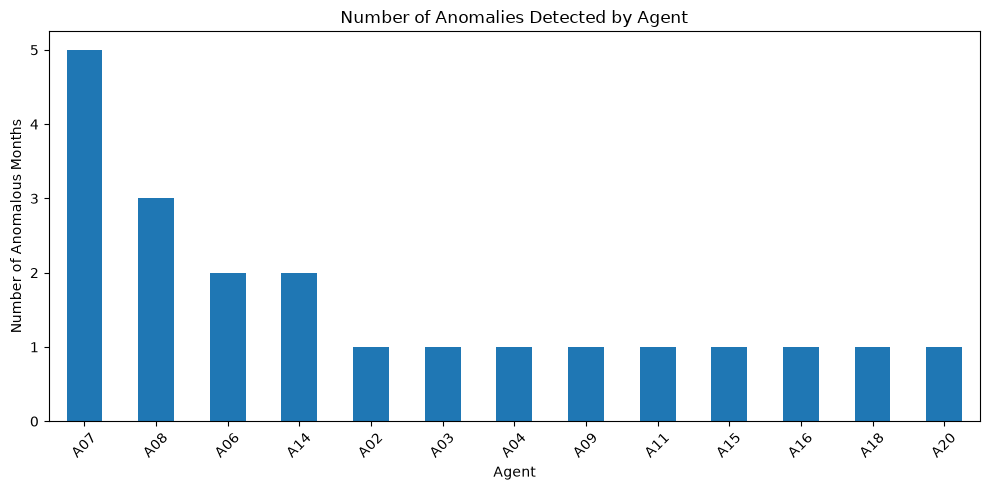

In [42]:
plt.figure(figsize=(10, 5))

anomaly_count.plot(kind="bar")

plt.title("Number of Anomalies Detected by Agent")
plt.xlabel("Agent")
plt.ylabel("Number of Anomalous Months")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()